# Experiment 2: where the errors come from, and what the models look at

This notebook asks, with stored predictions and the patch tables only, whether the models agree with the label of the patch or with the diagnosis of the picture the patch comes from, and where the errors collect. The order follows the plan: first the twelve models as a panel, then the label-authority test, then the other free analyses (error rates by agreement, severity skipping, colour, overlap), and at the end attribution maps for a few patches.

Two cautions that apply to everything below. The twelve models share their training data, folds and preprocessing, so how much they agree measures how much the answer depends on the architecture with the data held fixed. It is not agreement between independent observers. And the test fold has only about 10 patients and 39 pictures, so the patches of a picture count as one observation more than as many.

Run it from the training repository with `uv run jupyter lab notebooks/exp2_explainability.ipynb`. MLflow has to be running on this computer. The predictions are downloaded once and kept in `notebooks/cache` (delete a file there to download it again).

In [ ]:
import os
import shutil
import sys
import tempfile
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
from PIL import Image
from scipy import stats

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))
from src.config import load_env

EXPERIMENT = "ndb_ufes_exp2"
CACHE = REPO / "notebooks" / "cache"
ORGANIZER = REPO.parent / "ndb_ufes_data_organizer"
PATCHES = ORGANIZER / "data/ndb_ufes/patch_level/images"
CLASSES = ["Without dysplasia", "With dysplasia", "OSCC"]  # the class numbers 0, 1, 2
PROBABILITIES = ["prob_leukoplakia_without_dysplasia", "prob_leukoplakia_with_dysplasia", "prob_oscc"]

os.environ.setdefault("MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR", "false")
load_env(REPO / ".env", Path(os.getenv("MLFLOW_ENV_FILE", REPO.parent / "ndb_ufes_mlflow" / ".env")))
mlflow.set_tracking_uri(os.getenv("MLFLOW_TRACKING_URI", "http://localhost:8000/"))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 0. Load the data

`data` has the predictions of every fold run on the test fold. `meta` is the patch table of the organizer: one row for each of the 3,763 patches, with its picture, its patient group, where it sits in the picture, and the NDB-UFES diagnosis of the picture (`parent`).

In [ ]:
def load_predictions(experiment: str, kind: str = "heldout_predictions/predictions.csv") -> pd.DataFrame:
    """The predictions of all the fold runs of an experiment on the test fold, from MLflow (kept in notebooks/cache)."""
    cache = CACHE / f"{experiment}.csv"
    if cache.exists():
        return pd.read_csv(cache, keep_default_na=False)
    CACHE.mkdir(parents=True, exist_ok=True)
    runs = mlflow.search_runs(experiment_names=[experiment], filter_string="attributes.status = 'FINISHED'")
    folds = runs[runs["tags.mlflow.parentRunId"].notna()]
    frames = []
    for _, run in folds.iterrows():
        path = mlflow.artifacts.download_artifacts(run_id=run["run_id"], artifact_path=kind, dst_path=str(CACHE / "download" / run["run_id"]))
        frames.append(pd.read_csv(path, keep_default_na=False).assign(validation_fold=int(run["tags.validation_fold"])))
    frame = pd.concat(frames, ignore_index=True)
    frame.to_csv(cache, index=False)
    shutil.rmtree(CACHE / "download", ignore_errors=True)
    return frame


def prepare(frame: pd.DataFrame) -> pd.DataFrame:
    frame["y_true"], frame["y_pred"] = frame["y_true"].astype(int), frame["y_pred"].astype(int)
    frame["wrong"] = frame["y_true"] != frame["y_pred"]
    frame["true_name"] = frame["y_true"].map(dict(enumerate(CLASSES)))
    frame["pred_name"] = frame["y_pred"].map(dict(enumerate(CLASSES)))
    return frame


data = prepare(load_predictions(EXPERIMENT))
print(f"{len(data)} predictions: {data['model'].nunique()} models, {data['validation_fold'].nunique()} folds each, {data['patch_id'].nunique()} test patches")

meta = pd.read_csv(ORGANIZER / "results/phase0/dataset_tables/patch_table_public.csv", dtype=str, keep_default_na=False).set_index("patch_id")
for column in ("x", "y", "x2", "y2"):
    meta[column] = meta[column].astype(int)
LABEL = {"Leukoplakia without dysplasia": "Without dysplasia", "Leukoplakia with dysplasia": "With dysplasia", "OSCC": "OSCC"}
meta["label"] = meta["patch_diagnosis"].map(LABEL)  # the label of the patch
meta["parent"] = meta["ndb_diagnosis"].map(LABEL).fillna("not in NDB-UFES")  # the diagnosis of its picture
print(f"{len(meta)} patches in the patch table, from {meta['histopath_id'].nunique()} pictures and {meta['case_group'].nunique()} patient groups")

39360 predictions: 12 models, 5 folds each, 656 test patches
3763 patches in the patch table, from 247 pictures and 63 patient groups


## A. The twelve models as a panel

For each patch, what each model says (the class with the highest mean probability over the five fold runs of that model), and then how the twelve agree:

* `n_correct`: how many of the twelve models get it right (0 to 12)
* `consensus`: the class most models say (a tie goes to the less severe class)
* `mean_severity`: the mean of the predicted class numbers (without 0, with 1, OSCC 2), a continuous severity estimate
* `share_oscc`: the share of the models that say OSCC
* `disagreement`: the entropy of the twelve answers, in bits (0 when they all agree)

If `n_correct` has a mass at 12 and a mass at 0 with little between, the difficulty is in the patches. If it is spread in the middle, the architecture matters.

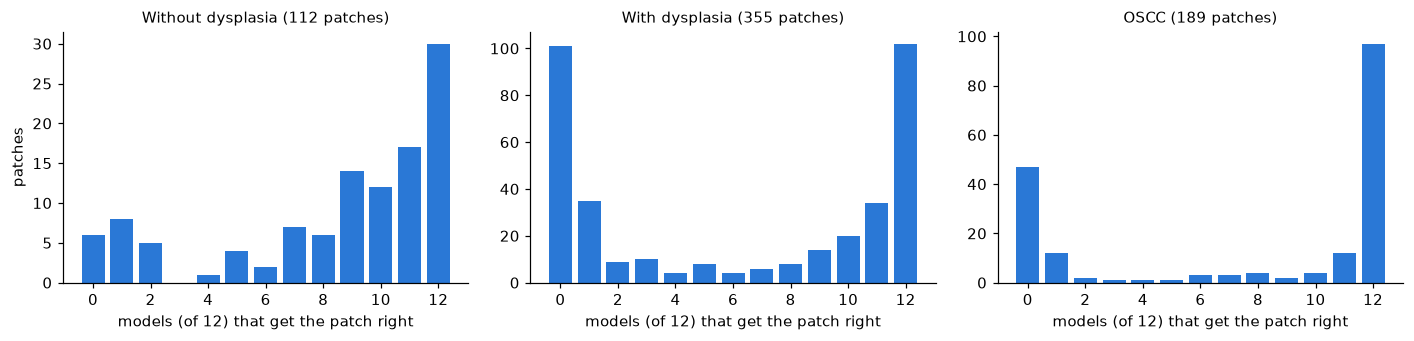

n_correct,0,1,2,3,4,5,6,7,8,9,10,11,12
true,,,,,,,,,,,,,
Without dysplasia,6,8,5,0,1,4,2,7,6,14,12,17,30
With dysplasia,101,35,9,10,4,8,4,6,8,14,20,34,102
OSCC,47,12,2,1,1,1,3,3,4,2,4,12,97


mean predicted severity by true class (0 without, 1 with dysplasia, 2 OSCC):


,mean,std,size
true,,,
Without dysplasia,0.370,0.495,112
With dysplasia,1.284,0.582,355
OSCC,1.632,0.459,189


In [ ]:
def panel_of(frame: pd.DataFrame) -> pd.DataFrame:
    """One row for each patch: what each model says, and how the models agree. Works on the test predictions and on the validation predictions."""
    by_model = frame.groupby(["patch_id", "model"])[PROBABILITIES].mean()
    calls = pd.Series(by_model.to_numpy().argmax(axis=1), index=by_model.index).unstack("model")  # patches x models: the class number each model says
    truth = frame.drop_duplicates("patch_id").set_index("patch_id")["y_true"].loc[calls.index]
    n = calls.shape[1]
    shares = np.stack([calls.eq(c).sum(axis=1) / n for c in range(3)], axis=1)
    panel = pd.DataFrame(index=calls.index)
    panel["true"] = truth.map(dict(enumerate(CLASSES)))
    panel["n_correct"] = calls.eq(truth, axis=0).sum(axis=1)
    panel["consensus"] = pd.Series(shares.argmax(axis=1), index=calls.index).map(dict(enumerate(CLASSES)))
    panel["mean_severity"] = calls.mean(axis=1)
    panel["share_oscc"] = shares[:, 2]
    panel["disagreement"] = stats.entropy(shares.T, base=2)
    panel = panel.join(meta[["label", "parent", "histopath_id", "case_group"]])
    panel.attrs["n_models"] = n  # after the join, which would drop it
    return panel


panel = panel_of(data)
N_MODELS = panel.attrs["n_models"]
counts = pd.crosstab(panel["true"], panel["n_correct"]).reindex(index=CLASSES, columns=range(N_MODELS + 1), fill_value=0)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharex=True)
for axis, name in zip(axes, CLASSES):
    axis.bar(counts.columns, counts.loc[name], color="#2a78d6")
    axis.set_title(f"{name} ({counts.loc[name].sum()} patches)", fontsize=10)
    axis.set_xlabel(f"models (of {N_MODELS}) that get the patch right")
axes[0].set_ylabel("patches")
plt.tight_layout()
plt.show()
display(counts)
print("mean predicted severity by true class (0 without, 1 with dysplasia, 2 OSCC):")
display(panel.groupby("true")["mean_severity"].agg(["mean", "std", "size"]).round(3).loc[CLASSES])

## 1. The parent diagnosis and the patch label (gap G1)

How the label of a patch relates to the diagnosis of the picture it was cut from, for all 3,763 patches. The percentages in the first table are of each parent diagnosis (a row adds to 100); the second is of each patch label (a column adds to 100).

In [ ]:
counts_g1 = pd.crosstab(meta["parent"], meta["label"], margins=True).reindex(index=[*CLASSES, "not in NDB-UFES", "All"], columns=[*CLASSES, "All"])
display(counts_g1)
print("% of the patches of each parent diagnosis (rows add to 100):")
display(pd.crosstab(meta["parent"], meta["label"], normalize="index").mul(100).round(1).reindex(index=[*CLASSES, "not in NDB-UFES"], columns=CLASSES))
print("% of the patches of each label (columns add to 100):")
display(pd.crosstab(meta["parent"], meta["label"], normalize="columns").mul(100).round(1).reindex(index=[*CLASSES, "not in NDB-UFES"], columns=CLASSES))
print("only the test fold of this experiment:")
display(pd.crosstab(meta.loc[panel.index, "parent"], meta.loc[panel.index, "label"], margins=True))

label,Without dysplasia,With dysplasia,OSCC,All
parent,,,,
Without dysplasia,263,395,0,658
With dysplasia,298,582,54,934
OSCC,65,522,932,1519
not in NDB-UFES,81,431,140,652
All,707,1930,1126,3763


% of the patches of each parent diagnosis (rows add to 100):


label,Without dysplasia,With dysplasia,OSCC
parent,,,
Without dysplasia,40.0,60.0,0.0
With dysplasia,31.9,62.3,5.8
OSCC,4.3,34.4,61.4
not in NDB-UFES,12.4,66.1,21.5


% of the patches of each label (columns add to 100):


label,Without dysplasia,With dysplasia,OSCC
parent,,,
Without dysplasia,37.2,20.5,0.0
With dysplasia,42.1,30.2,4.8
OSCC,9.2,27.0,82.8
not in NDB-UFES,11.5,22.3,12.4


only the test fold of this experiment:


label,OSCC,With dysplasia,Without dysplasia,All
parent,,,,
OSCC,146,118,0,264
With dysplasia,0,114,53,167
Without dysplasia,0,67,49,116
not in NDB-UFES,43,56,10,109
All,189,355,112,656


## 2. The label-authority test

Split the patches of one label by the diagnosis of their parent picture. If the models call OSCC much more often when the parent is OSCC, they are agreeing with the parent against the patch label. `mean severity` uses all twelve models (without 0, with 1, OSCC 2). `by picture` is the same mean taken per picture first and then averaged, which shows how much a few pictures carry the result.

In [ ]:
def label_authority(frame: pd.DataFrame, label: str, parents: list[str]) -> pd.DataFrame:
    """The patches with this label, by the diagnosis of their parent picture: what the models say about them."""
    rows = []
    for parent in parents:
        group = frame[(frame["label"] == label) & (frame["parent"] == parent)]
        by_picture = group.groupby("histopath_id")["mean_severity"].mean()
        rows.append({"parent diagnosis": parent, "patches": len(group), "pictures": group["histopath_id"].nunique(),
                     "models saying OSCC, %": group["share_oscc"].mean() * 100, "consensus OSCC, % of patches": (group["consensus"] == "OSCC").mean() * 100,
                     "mean severity": group["mean_severity"].mean(), "mean severity, by picture": by_picture.mean()})
    return pd.DataFrame(rows).set_index("parent diagnosis").round(2)


print("patches labeled WITH DYSPLASIA, by the diagnosis of their parent picture:")
display(label_authority(panel, "With dysplasia", ["OSCC", "With dysplasia", "Without dysplasia", "not in NDB-UFES"]))
print("patches labeled OSCC, by the diagnosis of their parent picture:")
display(label_authority(panel, "OSCC", ["OSCC", "With dysplasia", "not in NDB-UFES"]))
print("patches labeled WITHOUT DYSPLASIA, by the diagnosis of their parent picture:")
display(label_authority(panel, "Without dysplasia", ["With dysplasia", "Without dysplasia", "OSCC", "not in NDB-UFES"]))

patches labeled WITH DYSPLASIA, by the diagnosis of their parent picture:


,patches,pictures,"models saying OSCC, %","consensus OSCC, % of patches",mean severity,"mean severity, by picture"
parent diagnosis,,,,,,
OSCC,118,9,94.21,98.31,1.94,1.90
With dysplasia,114,8,18.64,16.67,1.09,1.01
Without dysplasia,67,6,4.48,1.49,0.91,0.86
not in NDB-UFES,56,6,1.93,1.79,0.75,0.85


patches labeled OSCC, by the diagnosis of their parent picture:


,patches,pictures,"models saying OSCC, %","consensus OSCC, % of patches",mean severity,"mean severity, by picture"
parent diagnosis,,,,,,
OSCC,146,8,82.59,83.56,1.83,1.83
With dysplasia,0,0,NaN,NaN,NaN,NaN
not in NDB-UFES,43,3,1.16,0.00,0.97,0.97


patches labeled WITHOUT DYSPLASIA, by the diagnosis of their parent picture:


,patches,pictures,"models saying OSCC, %","consensus OSCC, % of patches",mean severity,"mean severity, by picture"
parent diagnosis,,,,,,
With dysplasia,53,6,1.57,1.89,0.26,0.26
Without dysplasia,49,5,0.51,0.00,0.25,0.25
OSCC,0,0,NaN,NaN,NaN,NaN
not in NDB-UFES,10,2,70.00,80.00,1.52,0.85


The test fold has no OSCC patch whose picture is labeled with dysplasia (they are in other folds), so some rows above are empty. The validation predictions, if you have made them (`uv run python -m src.validation_predictions --experiment ndb_ufes_exp2`), cover the other five folds: every patch outside the test fold is predicted once by each model, by the models that did not train on it. The same table on them:

In [ ]:
VALIDATION = CACHE / f"{EXPERIMENT}_validation.csv"
if VALIDATION.exists():
    validation = prepare(pd.read_csv(VALIDATION, keep_default_na=False))
    panel_validation = panel_of(validation)
    print(f"{len(panel_validation)} patches outside the test fold, predicted by {panel_validation.attrs['n_models']} models")
    for label, parents in [("With dysplasia", ["OSCC", "With dysplasia", "Without dysplasia", "not in NDB-UFES"]), ("OSCC", ["OSCC", "With dysplasia", "not in NDB-UFES"]), ("Without dysplasia", ["With dysplasia", "Without dysplasia", "OSCC", "not in NDB-UFES"])]:
        print(f"\npatches labeled {label.upper()}, by the diagnosis of their parent picture (validation folds):")
        display(label_authority(panel_validation, label, parents))
else:
    print("No validation predictions yet:", VALIDATION)

No validation predictions yet: /Users/beamaia/thesis_organization/ndb_ufes_training_pipeline/notebooks/cache/ndb_ufes_exp2_validation.csv


## 3. Error rates when the label agrees with the parent and when it does not

Within each patch label: the error rate (the share of the twelve models that get the patch wrong, averaged over the patches) of the patches whose label is the diagnosis of their picture, against the patches whose label is not. A picture has one diagnosis, so within one label the agreeing and the discordant patches come from different pictures: they cannot be matched picture by picture. What can be done is to take the picture as the unit, with a bootstrap that resamples whole pictures, which gives a confidence interval that does not count the patches of a picture as independent. The second table compares, inside the same picture, the patches that agree with it and those that do not. That one mixes labels, so it is only a rough guide.

In [ ]:
known = panel[panel["parent"] != "not in NDB-UFES"].copy()
known["discordant"] = known["label"] != known["parent"]
known["error_rate"] = 1 - known["n_correct"] / N_MODELS


def bootstrap_difference(frame: pd.DataFrame, repeats: int = 5000, seed: int = 0) -> np.ndarray:
    """The 2.5, 50 and 97.5 percentiles of (error rate of the discordant patches) minus (error rate of the agreeing ones), resampling whole pictures."""
    by_picture = frame.groupby("histopath_id").apply(lambda g: pd.Series({"sum_d": g.loc[g["discordant"], "error_rate"].sum(), "n_d": g["discordant"].sum(), "sum_a": g.loc[~g["discordant"], "error_rate"].sum(), "n_a": (~g["discordant"]).sum()}), include_groups=False)
    values = by_picture.to_numpy(dtype=float)
    rng = np.random.default_rng(seed)
    picks = rng.integers(0, len(values), size=(repeats, len(values)))
    sampled = values[picks].sum(axis=1)  # repeats x 4
    with np.errstate(invalid="ignore", divide="ignore"):
        differences = sampled[:, 0] / sampled[:, 1] - sampled[:, 2] / sampled[:, 3]
    return np.nanpercentile(differences, [2.5, 50, 97.5])


rows = []
for label in CLASSES:
    group = known[known["label"] == label]
    if group["discordant"].nunique() < 2:
        rows.append({"label": label, "note": "only one kind of patch in this test fold", "patches (agree / discordant)": f"{(~group['discordant']).sum()} / {group['discordant'].sum()}"})
        continue
    low, middle, high = bootstrap_difference(group)
    rows.append({"label": label, "patches (agree / discordant)": f"{(~group['discordant']).sum()} / {group['discordant'].sum()}", "pictures (agree / discordant)": f"{group.loc[~group['discordant'], 'histopath_id'].nunique()} / {group.loc[group['discordant'], 'histopath_id'].nunique()}",
                 "error rate, agree": group.loc[~group["discordant"], "error_rate"].mean(), "error rate, discordant": group.loc[group["discordant"], "error_rate"].mean(),
                 "difference": middle, "95% interval (pictures resampled)": f"{low:.2f} to {high:.2f}"})
display(pd.DataFrame(rows).set_index("label").round(3))

per_picture = known.groupby(["histopath_id", "discordant"])["error_rate"].mean().unstack()
both = per_picture.dropna()
if len(both):
    differences = both[True] - both[False]
    print(f"inside the same picture: {len(both)} pictures have both agreeing and discordant patches; the discordant patches are wrong more often in {(differences > 0).sum()} and less often in {(differences < 0).sum()}; mean difference {differences.mean():.3f}")
    if len(both) >= 6:
        print("Wilcoxon signed-rank test on the picture differences:", stats.wilcoxon(differences))

,patches (agree / discordant),pictures (agree / discordant),"error rate, agree","error rate, discordant",difference,95% interval (pictures resampled),note
label,,,,,,,
Without dysplasia,49 / 53,5 / 6,0.248,0.244,-0.007,-0.17 to 0.21,NaN
With dysplasia,114 / 185,8 / 15,0.285,0.668,0.393,-0.02 to 0.71,NaN
OSCC,146 / 0,NaN,NaN,NaN,NaN,NaN,only one kind of patch in this test fold


inside the same picture: 9 pictures have both agreeing and discordant patches; the discordant patches are wrong more often in 6 and less often in 3; mean difference 0.265
Wilcoxon signed-rank test on the picture differences: WilcoxonResult(statistic=np.float64(10.0), pvalue=np.float64(0.1640625))


## 4. How often the models skip a severity step

The models predict an ordered scale, so the worst error is a jump over the middle class: OSCC called without dysplasia, or the reverse. The skipping rate is the share of predictions that do this.

In [ ]:
data["skips"] = (data["y_true"] - data["y_pred"]).abs() == 2
by_model = pd.DataFrame({
    "skipping, % of predictions": data.groupby("model")["skips"].mean() * 100,
    "skipping, % of the errors": data[data["wrong"]].groupby("model")["skips"].mean() * 100,
    "OSCC called without dysplasia": data[(data["y_true"] == 2) & (data["y_pred"] == 0)].groupby("model").size(),
    "without dysplasia called OSCC": data[(data["y_true"] == 0) & (data["y_pred"] == 2)].groupby("model").size(),
}).fillna(0).round(2).sort_values("skipping, % of predictions", ascending=False)
display(by_model)
print(f"over all models: {data['skips'].mean() * 100:.2f}% of the predictions skip a step, {data[data['wrong']]['skips'].mean() * 100:.2f}% of the errors")
print("what is the escalation? errors that go up a step against down a step:")
steps = (data["y_pred"] - data["y_true"])[data["wrong"]]
print(f"  up {(steps > 0).sum()} ({(steps > 0).mean() * 100:.1f}%), down {(steps < 0).sum()} ({(steps < 0).mean() * 100:.1f}%)")

,"skipping, % of predictions","skipping, % of the errors",OSCC called without dysplasia,without dysplasia called OSCC
model,,,,
efficientnet_b0,3.14,7.05,56,47
efficientnet_b3,2.99,6.35,64,34
pit_s_distilled_224,2.10,4.69,12,57
resnet50,2.01,4.25,17,49
swin_base_patch4_window7_224,1.98,4.32,9,56
densenet121,1.83,3.99,14,46
convnext_large,1.74,3.86,6,51
swin_tiny_patch4_window7_224,1.68,3.85,5,50
coat_lite_small,1.62,3.70,2,51


over all models: 1.92% of the predictions skip a step, 4.27% of the errors
what is the escalation? errors that go up a step against down a step:
  up 10644 (60.3%), down 7018 (39.7%)


## 5. Colour and stain

The mean colour of every patch in CIELAB (L is lightness, a goes from green to red, b from blue to yellow), computed once for all patches and kept in `notebooks/cache/patch_lab.csv`. The questions: does colour go with being wrong? does it differ between the classes? and how much of it belongs to the picture and to the patient, since if stain is a fingerprint of the picture, then under a patch-level random split a patch can be recognised by its colour.

In [ ]:
def lab_features(patch_ids) -> pd.DataFrame:
    """The mean and the standard deviation of L, a and b over the pixels of each patch (the white background counts as part of the patch)."""
    cache = CACHE / "patch_lab.csv"
    if cache.exists():
        return pd.read_csv(cache, index_col="patch_id")
    rows = {}
    for patch_id in patch_ids:
        rgb = np.asarray(Image.open(PATCHES / f"{patch_id}.png").convert("RGB"), dtype=np.float32) / 255
        lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB).reshape(-1, 3)
        rows[patch_id] = {"L": lab[:, 0].mean(), "a": lab[:, 1].mean(), "b": lab[:, 2].mean(), "L_sd": lab[:, 0].std(), "a_sd": lab[:, 1].std(), "b_sd": lab[:, 2].std()}
    frame = pd.DataFrame.from_dict(rows, orient="index").rename_axis("patch_id")
    frame.to_csv(cache)
    return frame


lab = lab_features(meta.index).join(meta[["label", "parent", "histopath_id", "case_group"]])
print(len(lab), "patches")
display(lab.groupby("label")[["L", "a", "b"]].agg(["mean", "std"]).round(2).loc[CLASSES])

3763 patches


L            a             b       
                    mean   std   mean    std   mean    std
label                                                     
Without dysplasia  57.83  4.71  25.16   9.99 -12.67   5.98
With dysplasia     57.70  4.28  28.80  12.41 -17.16  10.81
OSCC               58.17  4.41  34.22  11.26 -25.25  12.45

In [ ]:
def eta_squared(values: pd.Series, groups: pd.Series) -> float:
    """The share of the variance of the values that is the difference between the groups: 0 none, 1 all."""
    total = ((values - values.mean()) ** 2).sum()
    within = ((values - values.groupby(groups).transform("mean")) ** 2).sum()
    return 1 - within / total


print("share of the variance of each colour that belongs to the group (eta squared):")
display(pd.DataFrame({column: {"patch label": eta_squared(lab[column], lab["label"]), "picture": eta_squared(lab[column], lab["histopath_id"]), "patient group": eta_squared(lab[column], lab["case_group"])} for column in ["L", "a", "b"]}).round(3))
print("(a picture with only one patch has no variance of its own, so the share for pictures is somewhat high by construction; compare it with the patch label, which has few groups)")

from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

features = lab[["L", "a", "b", "L_sd", "a_sd", "b_sd"]]
several = lab["histopath_id"].map(lab["histopath_id"].value_counts()) >= 2  # a patch can only be matched to a picture that has another patch
scaled = StandardScaler().fit_transform(features[several])
for name, groups in [("picture", lab.loc[several, "histopath_id"]), ("patient group", lab.loc[several, "case_group"])]:
    guessed = cross_val_predict(KNeighborsClassifier(n_neighbors=1), scaled, groups, cv=LeaveOneOut())
    print(f"the {name} of a patch found from its colour alone (nearest other patch, leave one out): {(guessed == groups).mean() * 100:.1f}%; always guessing the biggest {name}: {groups.value_counts(normalize=True).iloc[0] * 100:.1f}%")

share of the variance of each colour that belongs to the group (eta squared):


,L,a,b
patch label,0.002,0.071,0.156
picture,0.529,0.964,0.973
patient group,0.183,0.513,0.556


(a picture with only one patch has no variance of its own, so the share for pictures is somewhat high by construction; compare it with the patch label, which has few groups)
the picture of a patch found from its colour alone (nearest other patch, leave one out): 77.5%; always guessing the biggest picture: 1.1%
the patient group of a patch found from its colour alone (nearest other patch, leave one out): 78.5%; always guessing the biggest patient group: 5.3%


In [ ]:
test = lab.loc[panel.index].join(panel[["n_correct"]])
test["error_rate"] = 1 - test["n_correct"] / N_MODELS
print("colour against the error rate of the patch in the test fold (Spearman correlation, and its p value):")
rows = {}
for column in ["L", "a", "b", "L_sd", "a_sd", "b_sd"]:
    overall = stats.spearmanr(test[column], test["error_rate"])
    rows[column] = {"all": f"{overall.statistic:+.2f} (p {overall.pvalue:.3f})", **{name: f"{stats.spearmanr(test.loc[test['label'] == name, column], test.loc[test['label'] == name, 'error_rate']).statistic:+.2f}" for name in CLASSES}}
display(pd.DataFrame(rows).T)
print("(the patches of a picture have almost the same colour and almost the same error rate, so the p values are too small: only 39 pictures are behind this)")
by_picture = test.groupby("histopath_id")[["L", "a", "b", "error_rate"]].mean()
print("the same, with one point for each picture:")
display(pd.DataFrame({column: dict(zip(["rho", "p"], stats.spearmanr(by_picture[column], by_picture["error_rate"]))) for column in ["L", "a", "b"]}).round(3))

colour against the error rate of the patch in the test fold (Spearman correlation, and its p value):


,all,Without dysplasia,With dysplasia,OSCC
L,+0.13 (p 0.001),+0.24,+0.09,+0.15
a,-0.06 (p 0.102),+0.16,-0.03,+0.01
b,+0.05 (p 0.165),-0.17,+0.06,+0.15
L_sd,+0.00 (p 0.972),-0.16,+0.05,-0.03
a_sd,+0.09 (p 0.027),-0.22,+0.25,-0.16
b_sd,+0.00 (p 0.950),-0.17,-0.03,+0.10


(the patches of a picture have almost the same colour and almost the same error rate, so the p values are too small: only 39 pictures are behind this)
the same, with one point for each picture:


,L,a,b
rho,0.099,-0.008,0.005
p,0.548,0.960,0.976


## 6. Overlap between patches, simulated with the real number of patches in each picture

The patches are 512 by 512 pixels cut from pictures of 2048 by 1536 (from 1 to 40 patches in a picture), and they can overlap. Under a random split of the patches into folds, a patch whose overlapping neighbour is in another fold has been partly seen in training. Here that is measured on the actual folds, and simulated: every picture gets as many patches as it really has (and, for comparison, a fixed 15), placed at random, and the patches go to six folds at random. Two patches overlap when they share at least a quarter of a patch (the threshold of the wiki).

In [ ]:
SIDE, WIDTH, HEIGHT, OVERLAP = 512, 2048, 1536, 0.25


def shared(x: np.ndarray, y: np.ndarray) -> np.ndarray:
    """For each pair of patches of one picture: the share of a patch that the other covers (the diagonal is 0)."""
    area = np.maximum(0, SIDE - np.abs(x[:, None] - x[None, :])) * np.maximum(0, SIDE - np.abs(y[:, None] - y[None, :])) / SIDE ** 2
    np.fill_diagonal(area, 0)
    return area


def exposed_share(x_by_picture: list, y_by_picture: list, folds_by_picture: list) -> float:
    """The share of the patches that have a neighbour that overlaps them, in another fold."""
    exposed = total = 0
    for x, y, folds in zip(x_by_picture, y_by_picture, folds_by_picture):
        overlapping = (shared(x, y) >= OVERLAP) & (folds[:, None] != folds[None, :])
        exposed += overlapping.any(axis=1).sum()
        total += len(x)
    return exposed / total


FOLDS = ORGANIZER / "results/phase1/folds"
folds_new = pd.read_csv(FOLDS / "fold_assignments.csv", dtype=str, keep_default_na=False).set_index("patch_id")["fold"]
folds_published = pd.read_csv(FOLDS / "fold_assignments_published.csv", dtype=str, keep_default_na=False).set_index("patch_id")["fold"]
placed = meta[meta["histopath_id"] != ""].copy()
placed["new"], placed["published"] = folds_new.reindex(placed.index), folds_published.reindex(placed.index)
placed = placed[(placed["new"] != "") & (placed["published"] != "")]  # the patches in the folds (the three duplicates are left out)
pictures = [group for _, group in placed.groupby("histopath_id")]
xs, ys = [g["x"].to_numpy() for g in pictures], [g["y"].to_numpy() for g in pictures]
print(f"{len(placed)} patches in {len(pictures)} pictures; patches per picture: median {np.median([len(g) for g in pictures]):.0f}, from {min(len(g) for g in pictures)} to {max(len(g) for g in pictures)}")
print(f"largest corner of a patch: x2 up to {placed['x2'].max()} of {WIDTH}, y2 up to {placed['y2'].max()} of {HEIGHT}")
print(f"observed, published folds: {exposed_share(xs, ys, [g['published'].to_numpy() for g in pictures]) * 100:.1f}% of the patches have an overlapping neighbour in another fold")
print(f"observed, new folds:       {exposed_share(xs, ys, [g['new'].to_numpy() for g in pictures]) * 100:.1f}%")

rng = np.random.default_rng(0)


def simulate(counts: list[int], repeats: int = 100) -> np.ndarray:
    """The exposed share when each picture has this many patches at random places and the patches go to six folds at random."""
    results = []
    for _ in range(repeats):
        x_all = [rng.integers(0, WIDTH - SIDE + 1, size=k) for k in counts]
        y_all = [rng.integers(0, HEIGHT - SIDE + 1, size=k) for k in counts]
        folds_all = [rng.integers(0, 6, size=k) for k in counts]
        results.append(exposed_share(x_all, y_all, folds_all))
    return np.array(results) * 100


actual = simulate([len(g) for g in pictures])
fixed = simulate([15] * len(pictures))
print(f"simulated, the real patches per picture: {actual.mean():.1f}% (range {actual.min():.1f} to {actual.max():.1f})")
print(f"simulated, 15 patches in every picture:  {fixed.mean():.1f}% (range {fixed.min():.1f} to {fixed.max():.1f})")

3760 patches in 247 pictures; patches per picture: median 16, from 1 to 40
largest corner of a patch: x2 up to 2048 of 2048, y2 up to 1536 of 1536
observed, published folds: 94.7% of the patches have an overlapping neighbour in another fold
observed, new folds:       0.0%
simulated, the real patches per picture: 90.8% (range 89.6 to 91.8)
simulated, 15 patches in every picture:  90.7% (range 89.2 to 92.2)


## 7. How much of the test fold was exposed (Experiment 1 against Experiment 2)

For each test patch and each fold run: the largest overlap (intersection over union) with a patch of the same picture that was in the training folds of that run (all folds except the test fold and the validation fold of the run). Then the error rate against that exposure, in bins. No training is needed. For Experiment 2 the exposure should be zero for every patch, because a picture is in one fold only, which is a check of the code. For Experiment 1 it is the dose-response of the leakage: if patches with a larger overlap are classified better, the leak helps the models.

Experiment 1 has to be finished (or at least some models of it). Its predictions are kept in `notebooks/cache/ndb_ufes_exp1.csv`: delete that file to download the models that finished since.

In [ ]:
def exposure(folds: pd.Series, test_patches, test_fold: str = "5") -> pd.DataFrame:
    """For each test patch (rows) and each other fold (columns): the largest IoU with a patch of the same picture in that fold."""
    others = sorted(set(folds[folds != ""]) - {test_fold})
    frame = meta.loc[list(test_patches), ["histopath_id", "x", "y"]]
    result = pd.DataFrame(0.0, index=frame.index, columns=others)
    for _, group in frame.groupby("histopath_id"):
        same = meta[(meta["histopath_id"] == group["histopath_id"].iloc[0])]
        same_folds = folds.reindex(same.index).to_numpy()
        for patch_id, row in group.iterrows():
            inter = np.maximum(0, SIDE - np.abs(same["x"].to_numpy() - row["x"])) * np.maximum(0, SIDE - np.abs(same["y"].to_numpy() - row["y"]))
            iou = inter / (2 * SIDE ** 2 - inter)
            iou[same.index == patch_id] = 0
            for fold in others:
                in_fold = same_folds == fold
                result.loc[patch_id, fold] = iou[in_fold].max() if in_fold.any() else 0.0
    return result


def leak_table(frame: pd.DataFrame, folds: pd.Series, title: str) -> None:
    patch_exposure = exposure(folds, frame["patch_id"].unique())
    # a run that has fold v as its validation fold did not train on fold v
    frame = frame.copy()
    frame["exposure"] = [patch_exposure.loc[p].drop(labels=str(v)).max() for p, v in zip(frame["patch_id"], frame["validation_fold"])]
    bins = pd.cut(frame["exposure"], [-0.001, 0, 0.1, 0.3, 0.6, 1.0], labels=["none", "up to 0.1", "0.1 to 0.3", "0.3 to 0.6", "over 0.6"])
    table = frame.groupby(bins, observed=True).agg(predictions=("wrong", "size"), patches=("patch_id", "nunique"), error_rate=("wrong", "mean"))
    table["error_rate"] = (table["error_rate"] * 100).round(1)
    print(f"{title}: error rate by the largest overlap with a training patch of the same picture")
    display(table)
    per_patch = frame.groupby("patch_id").agg(exposure=("exposure", "mean"), error_rate=("wrong", "mean"))
    if per_patch["exposure"].nunique() > 1:
        print("Spearman correlation of the exposure with the error rate, one point for each patch:", stats.spearmanr(per_patch["exposure"], per_patch["error_rate"]))


leak_table(data, folds_new, f"{EXPERIMENT} (new folds)")
EXPERIMENT_1 = "ndb_ufes_exp1"
try:
    data_1 = prepare(load_predictions(EXPERIMENT_1))
    print(f"\n{len(data_1)} predictions of the models of {EXPERIMENT_1} that have finished: {sorted(data_1['model'].unique())}")
    leak_table(data_1, folds_published, f"{EXPERIMENT_1} (published folds)")
except Exception as error:
    print(f"\nNo predictions of {EXPERIMENT_1} yet ({type(error).__name__}: {str(error)[:80]})")

ndb_ufes_exp2 (new folds): error rate by the largest overlap with a training patch of the same picture


,predictions,patches,error_rate
exposure,,,
none,39360,656,44.9



4382 predictions of the models of ndb_ufes_exp1 that have finished: ['efficientnet_b0', 'mobilenetv2']
ndb_ufes_exp1 (published folds): error rate by the largest overlap with a training patch of the same picture


,predictions,patches,error_rate
exposure,,,
none,65,37,23.1
up to 0.1,219,89,18.3
0.1 to 0.3,927,280,13.5
0.3 to 0.6,2175,419,9.9
over 0.6,996,172,6.7


Spearman correlation of the exposure with the error rate, one point for each patch: SignificanceResult(statistic=np.float64(-0.12997433460451505), pvalue=np.float64(0.0011169037853154616))


## 8. Attribution maps (Grad-CAM, convolutional models only)

Grad-CAM weights the last convolutional feature map of a model by the gradient of a class score. The convolutional models have such a map (shape channels by height by width). ViT, Swin, PiT and CoaT do not: their blocks give a sequence of tokens, and a Grad-CAM for them needs a custom reshaping that is not the same measurement. So the maps here are for the CNNs only, and a comparison between a CNN and a transformer would be confounded by the method. For all the models with the same method, occlusion is the one to use (Captum has `Occlusion`: it covers a grid of windows with a baseline and measures the drop of the class score). The maps explain the class the model predicted, and they say where the evidence for that class is, not why.

Four groups of patches from the panel: the model agrees with the parent against the patch label; a genuine model error (the parent is dysplasia and the models still say OSCC); dysplasia patches that all the models get right; and the patches that no model gets right.

In [ ]:
import torch
from captum.attr import LayerAttribution, LayerGradCam
from torchvision import transforms

from src.checkpoint import load_checkpoint
from src.dataset.leakage_safe_organizer import DEFAULT_PREPROCESSING, MODEL_PREPROCESSING
from src.validation_predictions import best_checkpoint

TARGET_LAYER = {  # the last convolutional feature map of each CNN
    "resnet50": lambda m: m.model.layer4,
    "densenet121": lambda m: m.model.features,
    "vgg16": lambda m: m.model.features[-2],
    "mobilenetv2": lambda m: m.model.features[-1],
    "efficientnet_b0": lambda m: m.model.bn2,
}


def load_fold_model(model_name: str, fold: int):
    """The best checkpoint of a fold run, from MLflow, as a model on the cpu."""
    runs = mlflow.search_runs(experiment_names=[EXPERIMENT], filter_string=f"attributes.status = 'FINISHED' and tags.model = '{model_name}' and tags.validation_fold = '{fold}'")
    runs = runs[runs["tags.mlflow.parentRunId"].notna()]
    with tempfile.TemporaryDirectory() as scratch:
        model, _ = load_checkpoint(best_checkpoint(runs.iloc[0]["run_id"], Path(scratch)), "cpu", torch.float32)
    for module in model.modules():
        if hasattr(module, "inplace"):
            module.inplace = False  # the hooks of the attribution do not work with operations in place
    return model.eval()


def gradcam(model_name: str, fold: int, patch_ids):
    """The patches, the class the model predicts for each, and the Grad-CAM map for that class (0 to 1, at the size of the input)."""
    model = load_fold_model(model_name, fold)
    prep = MODEL_PREPROCESSING.get(model_name, DEFAULT_PREPROCESSING)  # the models of the article use the default
    transform = transforms.Compose([transforms.Resize((prep["size"], prep["size"])), transforms.ToTensor(), transforms.Normalize(prep["mean"], prep["std"])])
    images = [Image.open(PATCHES / f"{patch_id}.png").convert("RGB").resize((prep["size"], prep["size"])) for patch_id in patch_ids]
    batch = torch.stack([transform(Image.open(PATCHES / f"{patch_id}.png").convert("RGB")) for patch_id in patch_ids])
    with torch.no_grad():
        predicted = model(batch).argmax(dim=1)
    maps = LayerGradCam(model, TARGET_LAYER[model_name](model)).attribute(batch, target=predicted, relu_attributions=True)
    maps = LayerAttribution.interpolate(maps, batch.shape[-2:]).squeeze(1).detach().numpy()
    maps = maps / (maps.max(axis=(1, 2), keepdims=True) + 1e-8)
    return images, predicted.numpy(), maps


GROUPS = {
    "model agrees with the parent: labeled with dysplasia, parent OSCC, consensus OSCC": panel[(panel["label"] == "With dysplasia") & (panel["parent"] == "OSCC") & (panel["consensus"] == "OSCC")].index,
    "genuine model error: labeled with dysplasia, parent with dysplasia, consensus OSCC": panel[(panel["label"] == "With dysplasia") & (panel["parent"] == "With dysplasia") & (panel["consensus"] == "OSCC")].index,
    "all models right: labeled with dysplasia": panel[(panel["label"] == "With dysplasia") & (panel["n_correct"] == N_MODELS)].index,
    "no model right": panel[panel["n_correct"] == 0].index,
}
print({name: len(ids) for name, ids in GROUPS.items()})

{'model agrees with the parent: labeled with dysplasia, parent OSCC, consensus OSCC': 116, 'genuine model error: labeled with dysplasia, parent with dysplasia, consensus OSCC': 19, 'all models right: labeled with dysplasia': 102, 'no model right': 154}


/var/folders/t3/fy39bt8j63ddwlwrjcqwbvbr0000gn/T/ipykernel_66777/3880210278.py:19: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout(rect=(0, 0, 1, 0.97))


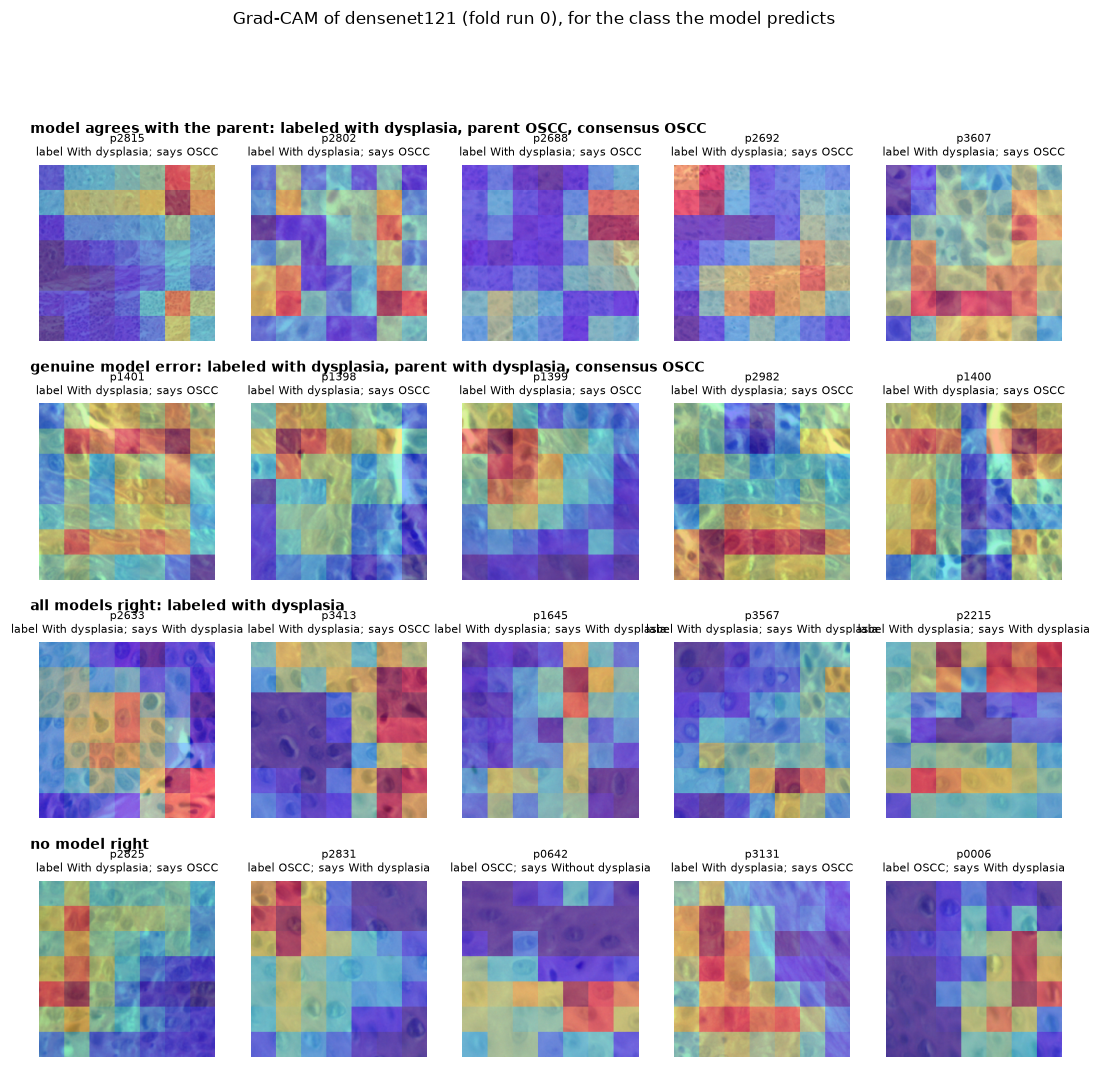

In [ ]:
MODEL_FOR_MAPS, FOLD_FOR_MAPS, PER_GROUP = "densenet121", 0, 5  # a CNN; change them to look at another model or fold run
rng = np.random.default_rng(0)
chosen = {name: list(rng.choice(ids, size=min(PER_GROUP, len(ids)), replace=False)) for name, ids in GROUPS.items() if len(ids)}
all_ids = [patch_id for ids in chosen.values() for patch_id in ids]
images, predicted, maps = gradcam(MODEL_FOR_MAPS, FOLD_FOR_MAPS, all_ids)
position = {patch_id: i for i, patch_id in enumerate(all_ids)}

fig, axes = plt.subplots(len(chosen), PER_GROUP, figsize=(2.4 * PER_GROUP, 2.7 * len(chosen)), squeeze=False)
for axis in axes.ravel():
    axis.axis("off")
for row, (name, ids) in enumerate(chosen.items()):
    for column, patch_id in enumerate(ids):
        i = position[patch_id]
        axes[row][column].imshow(images[i])
        axes[row][column].imshow(maps[i], cmap="jet", alpha=0.45)
        axes[row][column].set_title(f"{patch_id}\nlabel {panel.loc[patch_id, 'label']}; says {CLASSES[predicted[i]]}", fontsize=7)
    axes[row][0].text(-0.05, 1.18, name, transform=axes[row][0].transAxes, fontsize=9, fontweight="bold")
plt.suptitle(f"Grad-CAM of {MODEL_FOR_MAPS} (fold run {FOLD_FOR_MAPS}), for the class the model predicts", y=1.0, fontsize=11)
plt.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()